# Primary outcomes of behavioral chronic-pain trials: analysis

**Rebuilt automatically** by `finalize_cohort` (or alone: `PYTHONPATH=src python -m ctgov_pipeline.run_analysis`). Every figure is also saved to `analysis/figures/` (PNG 300 dpi + PDF) and the tables behind them to `analysis/tables/` (CSV), so this notebook is the single source of the article's figures. Do not edit the saved files by hand; change the code and rebuild.

Research question: among behavioral interventions for chronic pain (back pain, fibromyalgia, migraine, headache), which primary outcomes do researchers register, and how does this differ by intervention approach and over time?

Sections: **1** trials over time, **2** cohort summary table, **3** exclusion reasons, **4** conditions, **5** interventions, **6** intervention x outcome cross-tab (with filters), then additional views.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "analysis" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from ctgov_pipeline import analysis_data as ad
from ctgov_pipeline import analysis_plots as ap

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
ap.set_style()

studies, outcomes = ad.load_tables()
LABELS = ad.intervention_labels()
inc = ad.included(studies)


def show(fig, name):
    """Save the figure to analysis/figures/<name>.png|pdf and show it here."""
    ap.save_figure(fig, name)
    display(fig)
    plt.close(fig)


print(f"Extraction run {studies['extraction_run_id'].iloc[0]}, rules {studies['cohort_rules_version'].iloc[0]}: "
      f"{len(studies)} trials in the pool, {len(inc)} included, "
      f"{(outcomes['cohort_inclusion_status'] == 'included').sum()} primary-outcome rows in included trials.")

Extraction run full_20261109_104453, rules conditions_field_v3: 936 trials in the pool, 824 included, 1900 primary-outcome rows in included trials.


## 1. Trials over time

Included trials per year of first posting on ClinicalTrials.gov (excluded trials in grey on top, so the growth of the whole pool is visible too). Registration volume grows strongly after 2015; the latest year is partial.

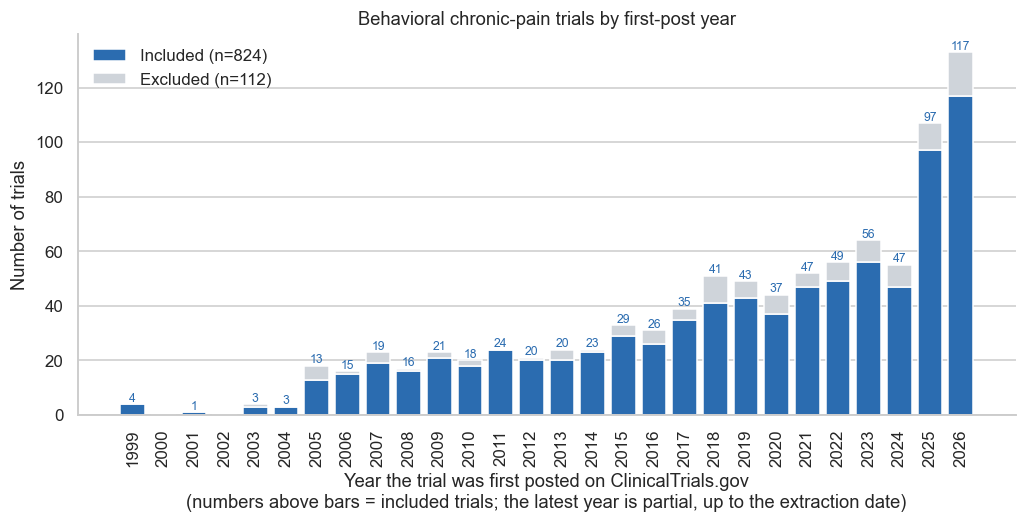

In [2]:
show(ap.plot_trials_by_year(studies), "fig01_trials_by_year")
yearly = studies.groupby(["first_post_year", "cohort_inclusion_status"]).size().unstack(fill_value=0)
ap.save_table(yearly, "tab01_trials_by_year")

## 2. Cohort summary table

Means and shares of "studies with more than one primary outcome" use the included trials that registered at least one primary outcome as denominator.

In [3]:
summary = ad.cohort_summary_table(studies, outcomes)
ap.save_table(summary, "tab02_cohort_summary", index=False)
display(summary.style.hide(axis="index"))

Metric,Value,Note
Master pool (before filtering),936,all trials retrieved from CT.gov
Final analytic cohort,824,88.0% of the pool
Excluded,112,12.0% of the pool
Primary outcome rows (included trials),"1,900",one row per registered primary outcome
Studies with more than one primary outcome,382,47.1% of the 811 included trials with a registered primary outcome
Mean primary outcomes per study,2.34,over the 811 included trials with a registered primary outcome
Multimodal intervention trials,101,12.3% of included (behavioral + an active non-behavioral arm)
Included trials with no registered primary outcome,13,no row in primary_outcomes.csv


## 3. Exclusion reasons

Each excluded trial is counted once, under the first rule that matched (`docs/COHORT_FILTERING_RULES.md`). Two strata, as stored in `exclusion_reason`: **condition eligibility** (the registered conditions or the population do not fit: cancer, other pathology, pregnancy, no target condition, subacute/perioperative, not about pain) and **pain-character eligibility** (acute pain, or a stated pain duration of 11 weeks or less).

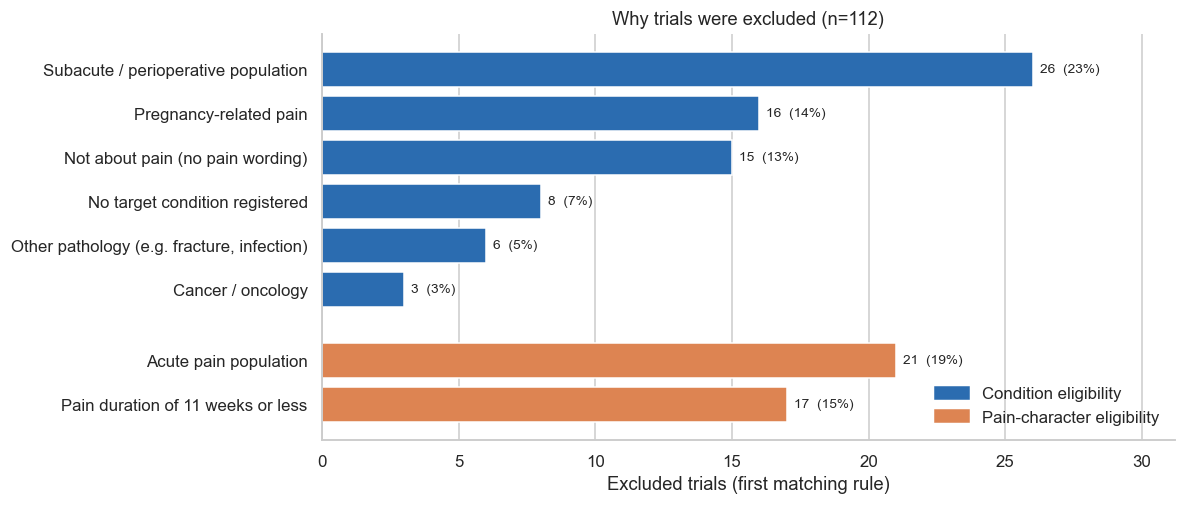

exclusion_stratum,exclusion_rule,trials
Condition eligibility,cancer_oncology,3
Condition eligibility,no_target_match,8
Condition eligibility,not_about_pain,15
Condition eligibility,pathology_other,6
Condition eligibility,pregnancy_related,16
Condition eligibility,subacute_perioperative,26
Pain-character eligibility,acute_pain,21
Pain-character eligibility,short_pain_window,17


In [4]:
show(ap.plot_exclusion_reasons(studies), "fig03_exclusion_reasons")
exclusions = (studies[studies["cohort_inclusion_status"] == "excluded"]
              .groupby(["exclusion_stratum", "exclusion_rule"]).size().rename("trials").reset_index())
ap.save_table(exclusions, "tab03_exclusion_reasons", index=False)
display(exclusions.style.hide(axis="index"))

## 4. Trials per pain condition

A condition counts when it is among the trial's **registered conditions** (the cohort filter). Many trials list more than one, so the left panel does not sum to the cohort size; the right panel counts every trial once by its exact combination. "Headache (other types)" means headache types other than plain migraine.

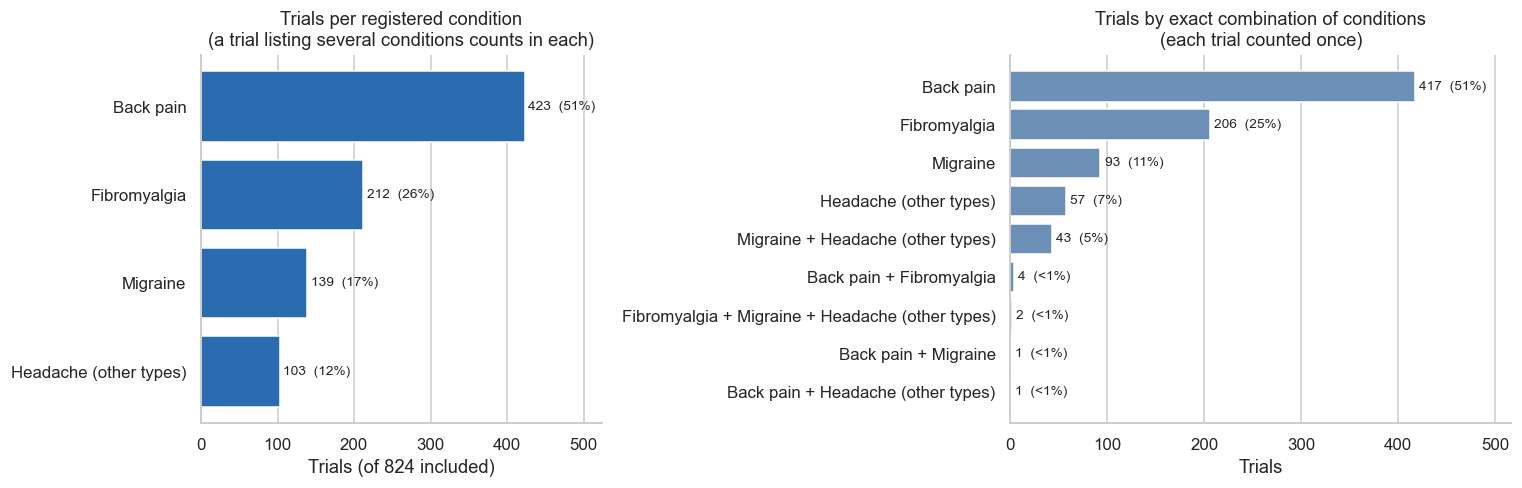

,trials,share_of_included
Back pain,423,0.513
Fibromyalgia,212,0.257
Migraine,139,0.169
Headache (other types),103,0.125


In [5]:
show(ap.plot_conditions(studies), "fig04_conditions")
cond = pd.DataFrame({"trials": {label: int(inc["condition_list"].apply(lambda l, x=label: x in l).sum()) for label in ad.CONDITION_LABELS.values()}})
cond["share_of_included"] = (cond["trials"] / len(inc)).round(3)
ap.save_table(cond, "tab04_conditions")
display(cond)

## 5. Trials per intervention category

The taxonomy (`config/intervention_categories.yaml`) is flat and multi-label: a trial carries every category matched by any **active** arm. Left: trials per category, split by whether the trial also has an active non-behavioral arm (multimodal). Right: the most common exact combinations, which separates trials with a single approach from combined ones. `other_behavioral_treatment` is the fallback for behavioral arms that match no category.

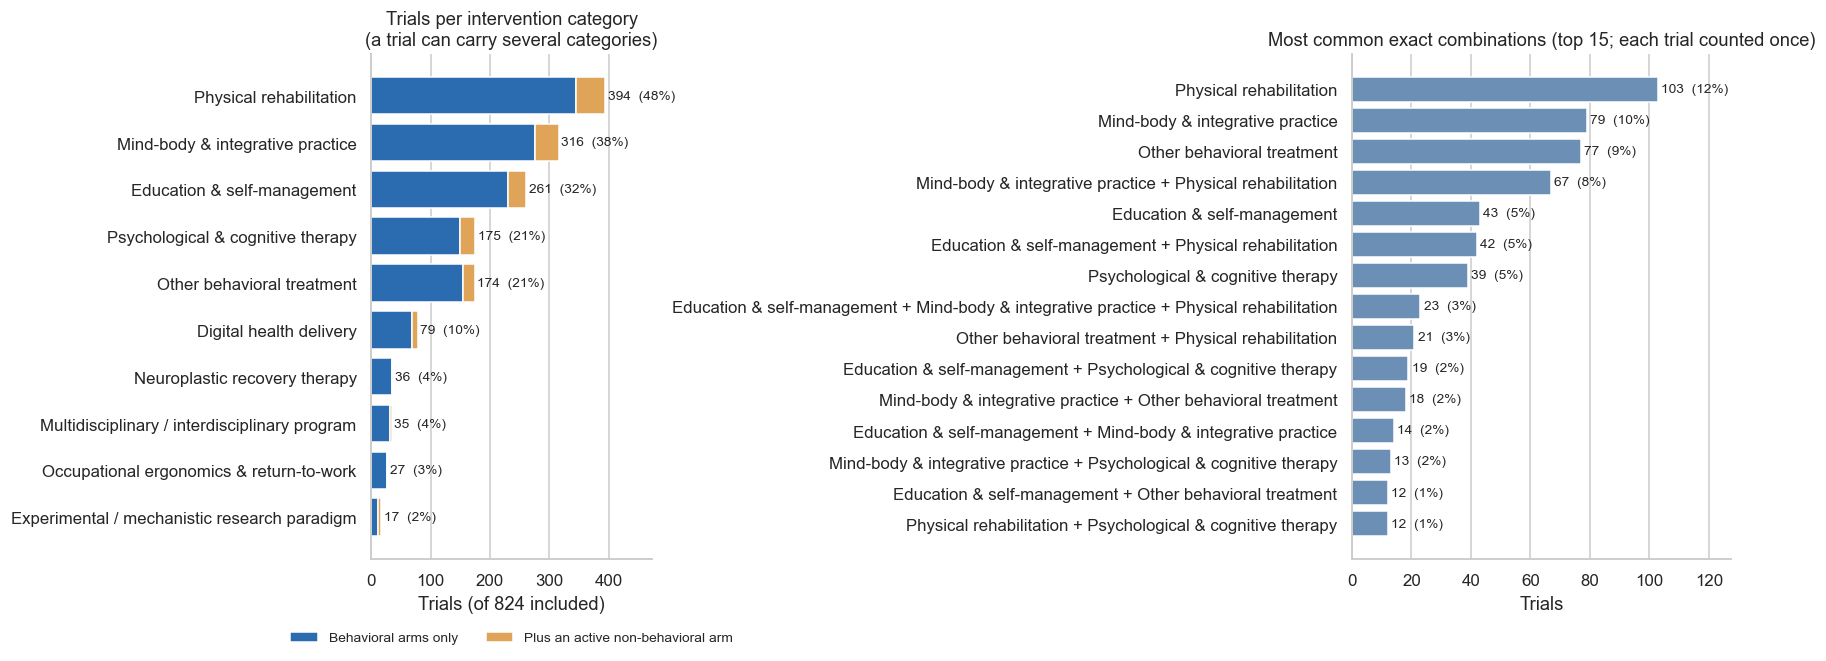

,trials,multimodal,share_of_included
category,,,
Physical rehabilitation,394,49,0.478
Mind-body & integrative practice,316,41,0.383
Education & self-management,261,31,0.317
Psychological & cognitive therapy,175,25,0.212
Other behavioral treatment,174,19,0.211
Digital health delivery,79,10,0.096
Neuroplastic recovery therapy,36,1,0.044
Multidisciplinary / interdisciplinary program,35,4,0.042
Occupational ergonomics & return-to-work,27,1,0.033


In [6]:
show(ap.plot_interventions(studies, LABELS), "fig05_interventions")
by_cat = (inc[["nct_id", "intervention_list", "is_multimodal"]].explode("intervention_list").dropna(subset=["intervention_list"])
          .assign(category=lambda d: d["intervention_list"].map(LABELS))
          .groupby("category").agg(trials=("nct_id", "nunique"), multimodal=("is_multimodal", "sum"))
          .sort_values("trials", ascending=False))
by_cat["share_of_included"] = (by_cat["trials"] / len(inc)).round(3)
ap.save_table(by_cat, "tab05_interventions")
display(by_cat)

### 5b. Which intervention categories appear together

Two views of the overlaps (a trial can carry several categories):

* **Heatmap:** read along a row. Of the trials with the *row* category, the percentage (and number) that also carry the *column* category. It is not symmetric: most education trials may also have exercise, while far fewer exercise trials have education, because the categories differ in size.
* **UpSet plot:** the standard way to show set overlaps. Each bar is the number of trials with *exactly* that combination (every trial counted once); the dots underneath show which categories the combination contains.

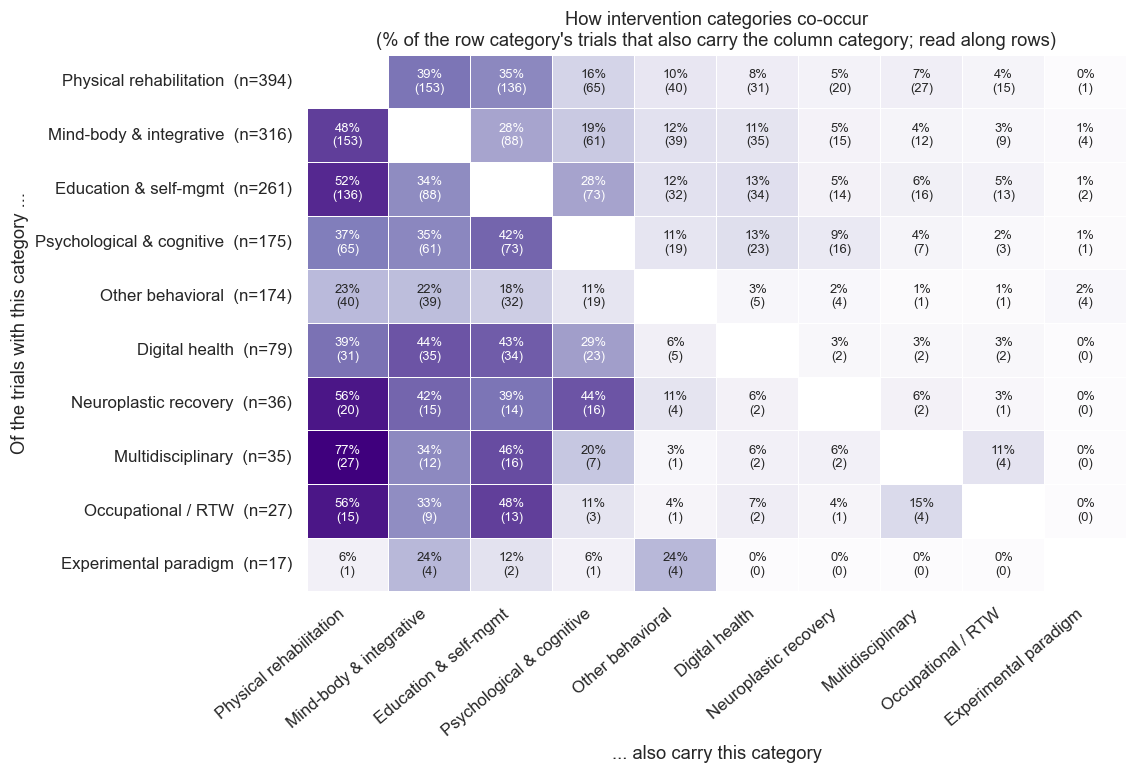

In [7]:
show(ap.plot_cooccurrence(studies), "fig13_cooccurrence_heatmap")
cooc = ad.cooccurrence(studies)
cooc.index = [ad.SHORT_LABELS.get(k, k) for k in cooc.index]
cooc.columns = [ad.SHORT_LABELS.get(k, k) for k in cooc.columns]
ap.save_table(cooc, "tab13_cooccurrence_counts")

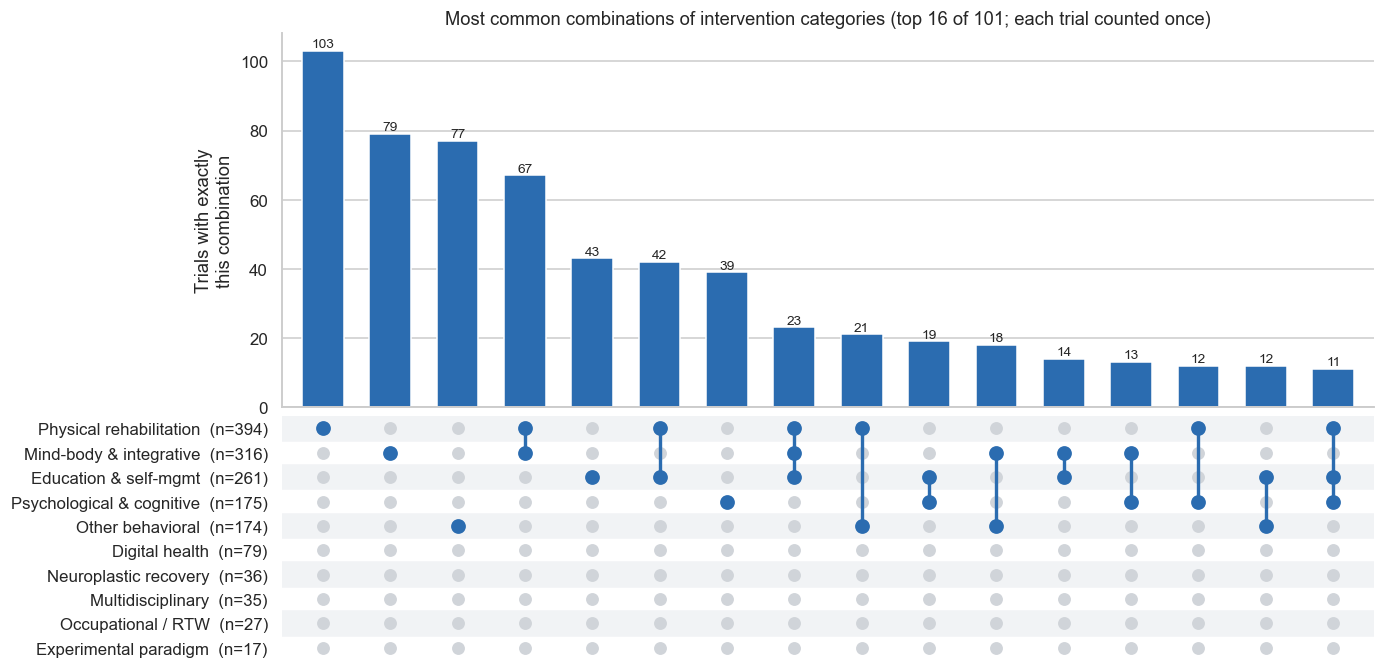

In [8]:
show(ap.plot_upset(studies), "fig14_upset_combinations")

## 6. Intervention category x outcome category

The main question of the study: which outcomes do trials of each intervention type register as primary?

**How to read the two panels**

* **Left panel (blue), outcome share.** Counts every individual primary outcome registered by the trials in that row. Read it as: "out of all outcome measures registered for psychological-therapy trials, A% are pain interference and B% are pain recovery". Each row adds up to 100%.
  *The catch:* trials register anywhere from 1 to 8 or more primary outcomes, so one trial with 6 feasibility outcomes inflates the feasibility share of its whole row.
* **Right panel (orange), trial share.** Counts the trials themselves: the percentage of trials in that row with **at least one** outcome of that type. Read it as: "C% of psychological-therapy trials measure pain interference at least once, D% measure pain recovery". A trial counts once per category however many outcomes it has, which fixes the catch above. A trial can measure several things (say interference and mood), so each row adds up to more than 100%.

The cell below the figure prints this example with the live numbers. Other notes: `not_an_outcome_measure` rows (baseline descriptors) are dropped and `other` is kept; rows marked `*` have fewer than 10 trials, so their percentages are unstable.

### Filters
Edit the two queries and re-run the cell below; the filtered figure is saved as `fig06_custom`. `STUDY_FILTER` is a pandas query on the trial table, `OUTCOME_FILTER` on the outcome rows. Useful trial columns: `is_multimodal`, `n_intervention_categories`, `has_<category>` (e.g. `has_psychological_cognitive`), `eligible_back_pain` / `eligible_fibromyalgia` / `eligible_migraine` / `eligible_headache`, `n_conditions`, `first_post_year`, `period`, `raw_overall_status`, `raw_phases`, `raw_has_results`, `raw_primary_purpose`, `control_arm_types`, `n_primary_outcomes`. Outcome columns: `outcome_category`, `outcome_subcategory`, `outcome_category_review_flag`, `instruments_detected`, `n_primary_outcomes_in_study`. Examples: `"is_multimodal == False"`, `"eligible_migraine and not eligible_back_pain"`, `"first_post_year >= 2018"`.

In [9]:
# --- Edit and re-run: filters for the custom cross-tab (None = no filter) ---
STUDY_FILTER = None    # e.g. "is_multimodal == False"
OUTCOME_FILTER = None  # e.g. "outcome_category_review_flag == False"

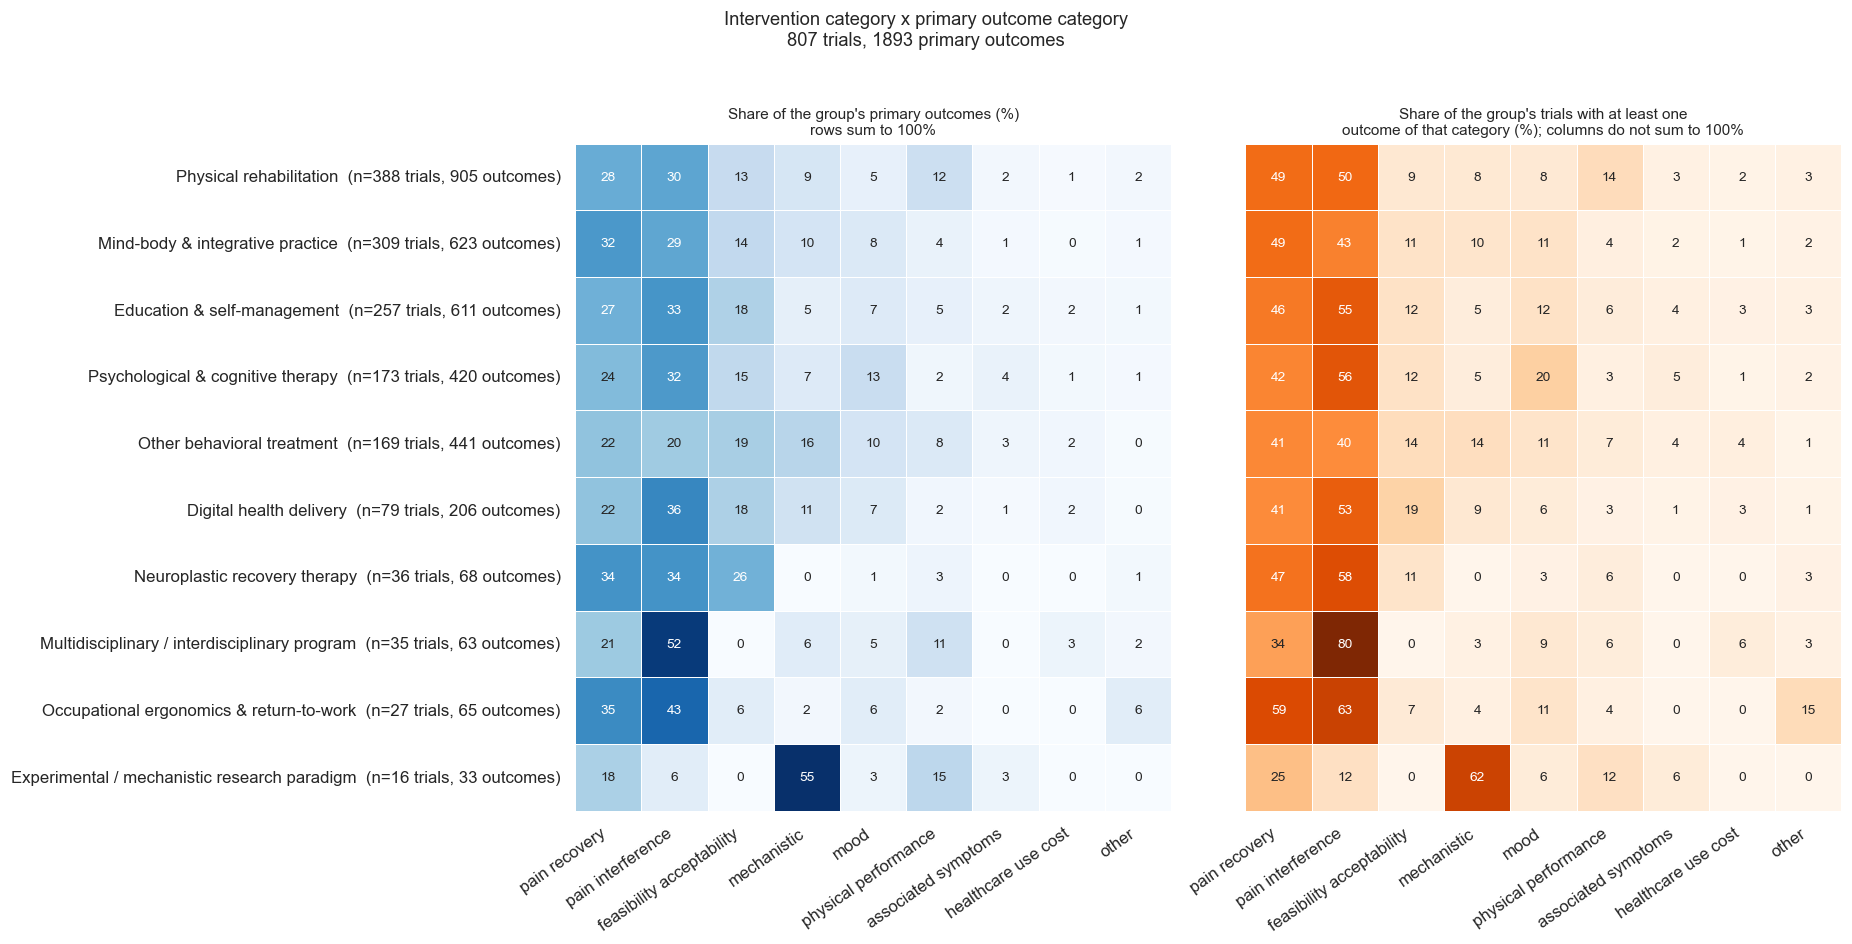

outcome_category,pain_recovery,pain_interference,feasibility_acceptability,mechanistic,mood,physical_performance,associated_symptoms,healthcare_use_cost,other,n_trials,n_outcomes
Physical rehabilitation,27.7,29.5,13.5,9.0,4.5,11.9,1.5,0.8,1.5,388,905
Mind-body & integrative practice,32.4,29.2,14.3,9.6,7.9,3.9,1.1,0.5,1.1,309,623
Education & self-management,26.8,33.4,17.5,4.9,7.2,4.6,2.5,1.6,1.5,257,611
Psychological & cognitive therapy,24.3,32.4,14.5,7.1,12.9,2.1,4.0,1.4,1.2,173,420
Other behavioral treatment,22.2,20.2,18.8,16.1,9.8,7.7,2.7,2.0,0.5,169,441
Digital health delivery,22.3,36.4,18.0,10.7,7.3,1.9,1.0,1.9,0.5,79,206
Neuroplastic recovery therapy,33.8,33.8,26.5,0.0,1.5,2.9,0.0,0.0,1.5,36,68
Multidisciplinary / interdisciplinary program,20.6,52.4,0.0,6.3,4.8,11.1,0.0,3.2,1.6,35,63
Occupational ergonomics & return-to-work,35.4,43.1,6.2,1.5,6.2,1.5,0.0,0.0,6.2,27,65
Experimental / mechanistic research paradigm,18.2,6.1,0.0,54.5,3.0,15.2,3.0,0.0,0.0,16,33


Psychological & cognitive therapy: 173 trials, 420 primary outcomes.
  Left (blue): of all 420 outcomes, 32% are pain interference and 24% are pain recovery (row adds up to 100%).
  Right (orange): 56% of the 173 trials measure pain interference at least once, 42% pain recovery and 20% mood (row adds up to 148%, because a trial can measure several things).


In [10]:
ct = ad.outcome_by_group(studies, outcomes, labels=LABELS)
show(ap.plot_crosstab(ct), "fig06_intervention_x_outcome")
ap.save_table(ct.row_percent().round(1), "tab06_intervention_x_outcome_row_percent")
ap.save_table(ct.trial_percent().round(1), "tab06_intervention_x_outcome_trial_percent")
ap.save_table(ct.rows, "tab06_intervention_x_outcome_rows_n")
ap.save_table(ct.trials, "tab06_intervention_x_outcome_trials_n")
display(ct.row_percent().round(1).assign(n_trials=ct.n_trials, n_outcomes=ct.n_rows))

# Live example of how to read the two panels (numbers update with every rebuild)
g = "Psychological & cognitive therapy"
rp, tp = ct.row_percent().loc[g], ct.trial_percent().loc[g]
print(f"{g}: {ct.n_trials[g]} trials, {ct.n_rows[g]} primary outcomes.")
print(f"  Left (blue): of all {ct.n_rows[g]} outcomes, {rp['pain_interference']:.0f}% are pain interference and {rp['pain_recovery']:.0f}% are pain recovery (row adds up to 100%).")
print(f"  Right (orange): {tp['pain_interference']:.0f}% of the {ct.n_trials[g]} trials measure pain interference at least once, "
      f"{tp['pain_recovery']:.0f}% pain recovery and {tp['mood']:.0f}% mood (row adds up to {tp.sum():.0f}%, because a trial can measure several things).")

In [11]:
if STUDY_FILTER or OUTCOME_FILTER:
    ct_custom = ad.outcome_by_group(studies, outcomes, labels=LABELS, study_query=STUDY_FILTER, outcome_query=OUTCOME_FILTER)
    title = f"Intervention category x outcome category | trials: {STUDY_FILTER or 'all'} | outcomes: {OUTCOME_FILTER or 'all'}"
    show(ap.plot_crosstab(ct_custom, title=title), "fig06_custom")
    ap.save_table(ct_custom.row_percent().round(1), "tab06_custom_row_percent")
else:
    print("No custom filter set (STUDY_FILTER / OUTCOME_FILTER above).")

No custom filter set (STUDY_FILTER / OUTCOME_FILTER above).


### Sensitivity versions (rebuilt every time)
A trial can combine approaches (yoga + CBT) or add a non-behavioral treatment (CBT + medication). The same two-panel heatmap is therefore recomputed on subsets, to check that the main picture is not distorted by these overlaps. Each figure title shows its number of trials and outcomes.

1. **Full cohort (main figure above).** Everything. A trial with several intervention categories (for example exercise + CBT) appears in each of its rows.
2. **`single_category`:** only trials with exactly one intervention category. *Purity check:* do the outcome patterns belong to that therapy itself, rather than to a co-intervention in the same trial? Groups become small, so watch the `*` rows.
3. **`unimodal`** (`is_multimodal == False`): removes trials where a behavioral treatment was paired with a drug, device or procedure arm. *Confounder check:* are the outcomes driven by the behavioral therapy, not by the added medication or stimulation?
4. **`completed`** (status `COMPLETED`): only finished trials. *Check* that the result is not driven by the many recent, not-yet-finished registrations (outcome choices change over time, see the time plot below).

If a pattern holds in all versions it is robust; a large shift between versions is worth reporting.


unimodal: 707 trials, 1675 primary outcomes


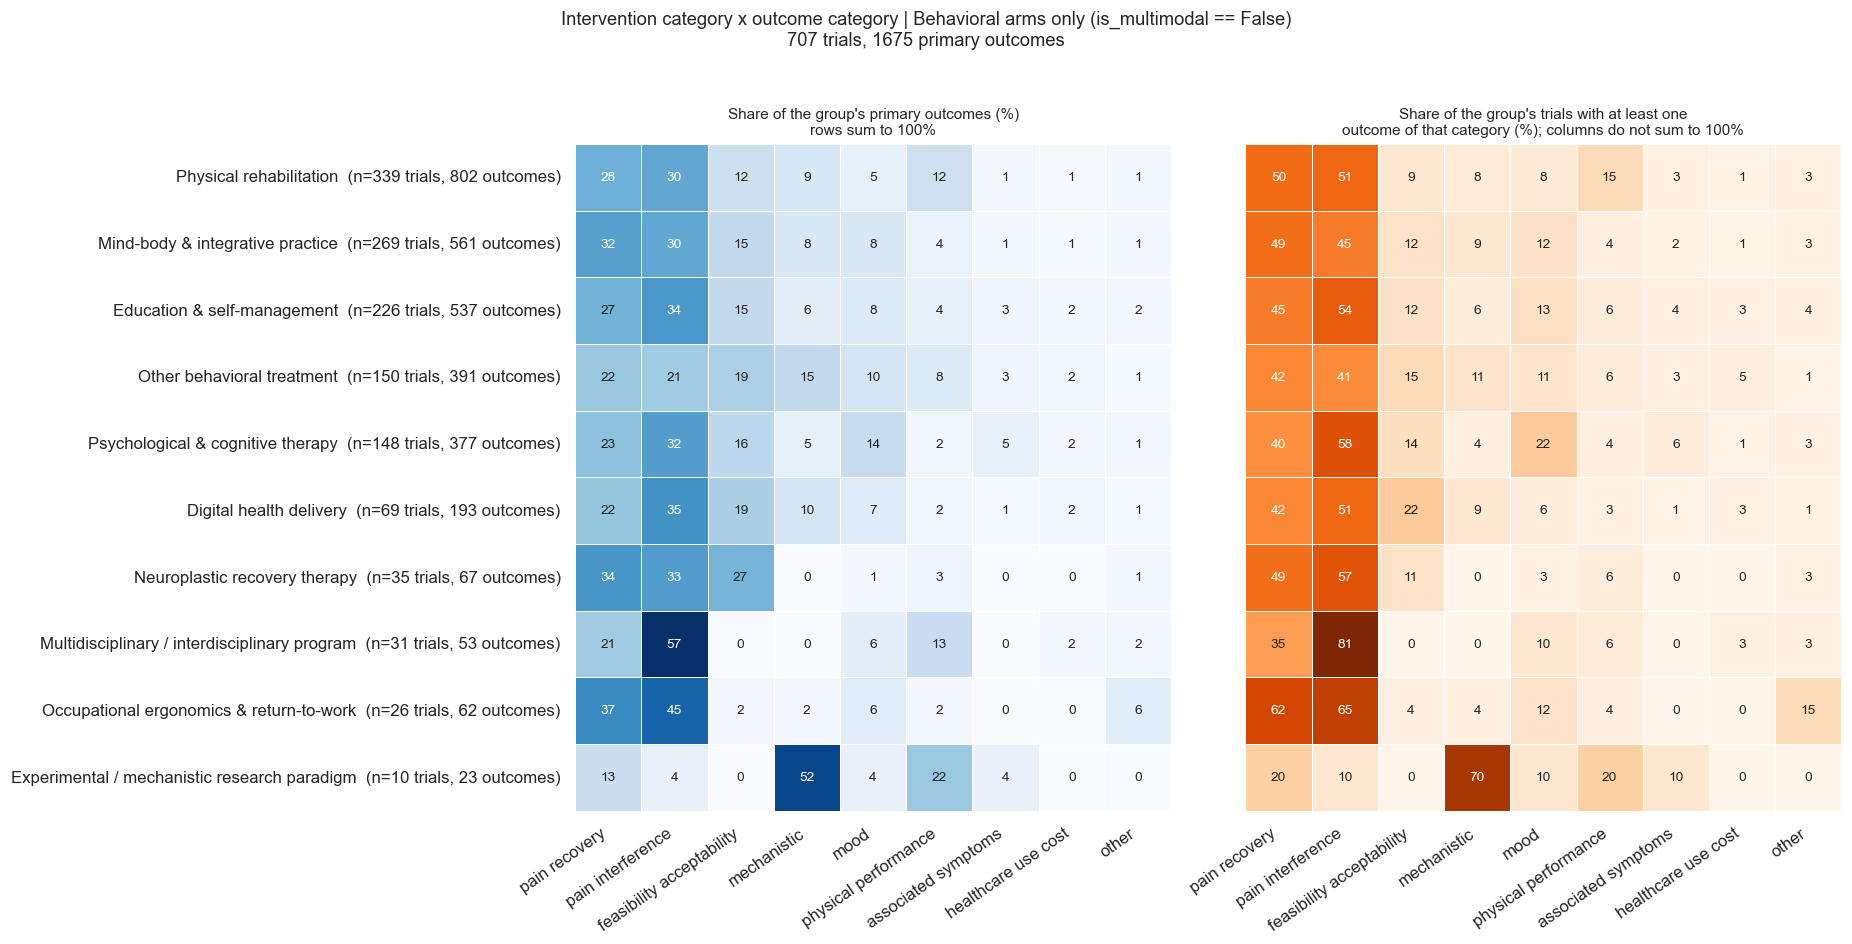

single_category: 367 trials, 861 primary outcomes


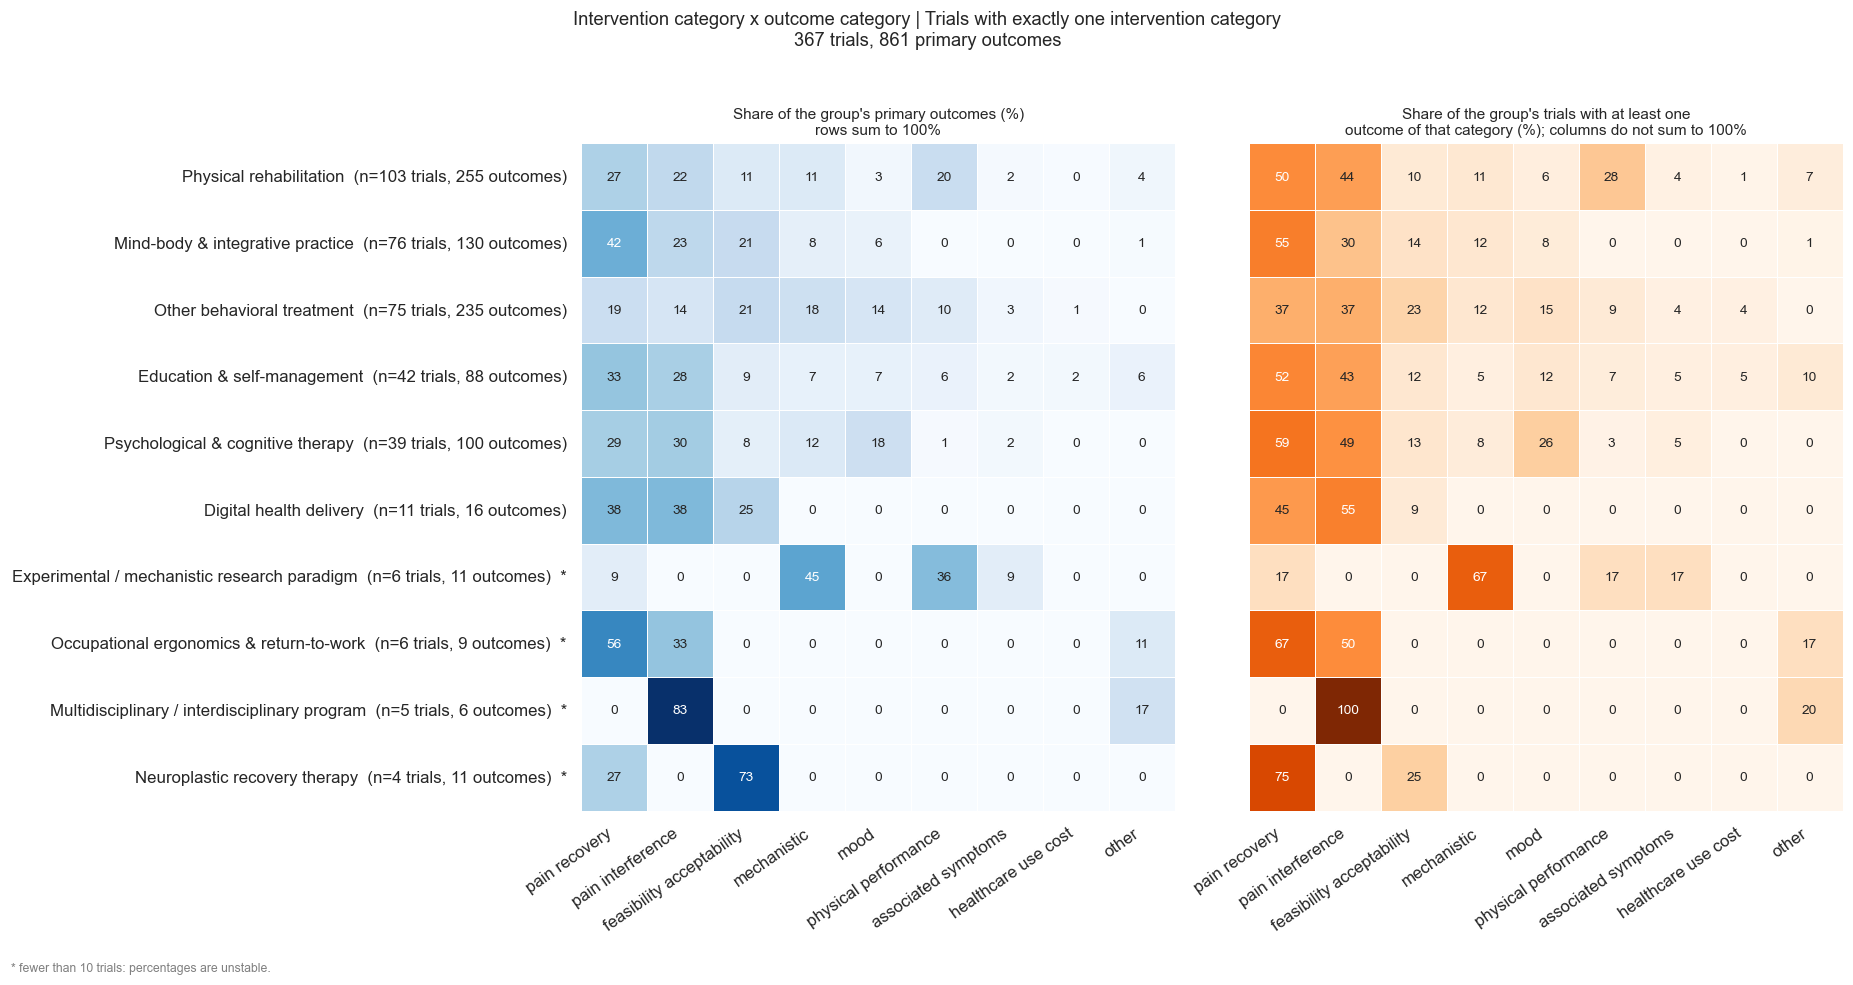

completed: 480 trials, 1128 primary outcomes


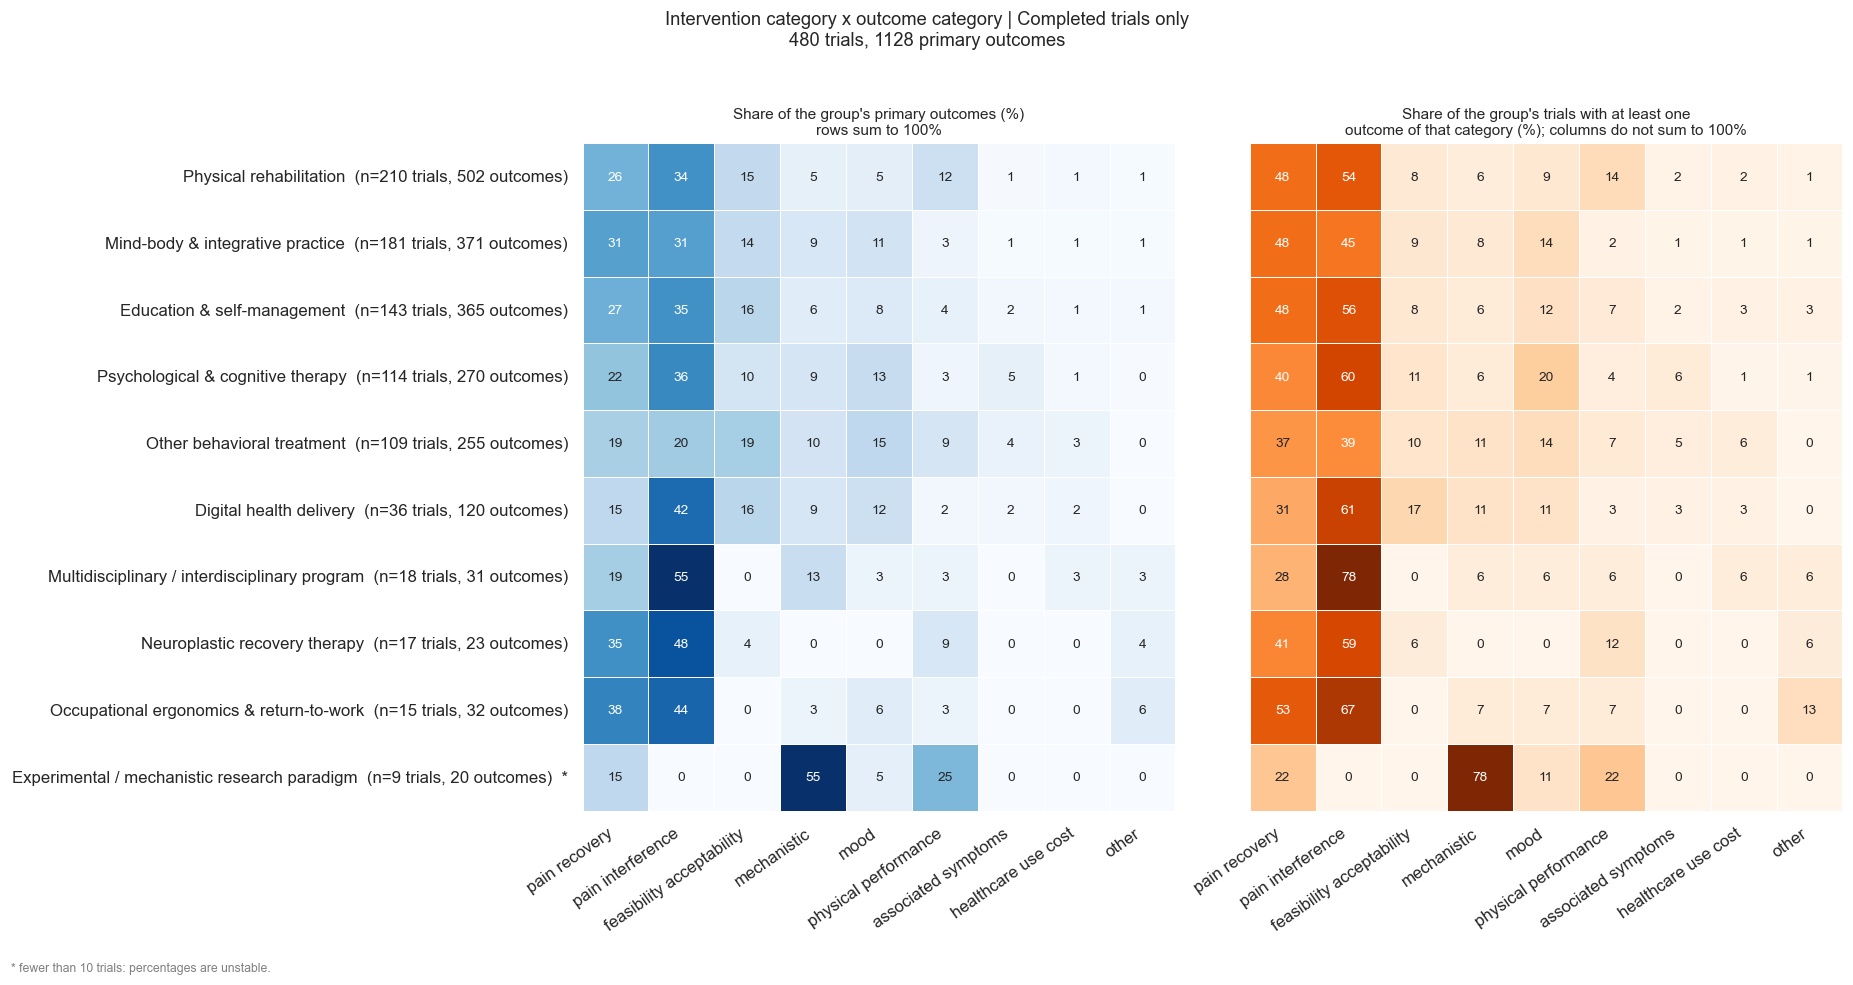

In [12]:
SENSITIVITY = {
    "unimodal": ("is_multimodal == False", "Behavioral arms only (is_multimodal == False)"),
    "single_category": ("n_intervention_categories == 1", "Trials with exactly one intervention category"),
    "completed": ("raw_overall_status == 'COMPLETED'", "Completed trials only"),
}
for key, (query, title) in SENSITIVITY.items():
    ct_s = ad.outcome_by_group(studies, outcomes, labels=LABELS, study_query=query)
    print(f"{key}: {ct_s.n_trials_total} trials, {ct_s.n_rows_total} primary outcomes")
    show(ap.plot_crosstab(ct_s, title=f"Intervention category x outcome category | {title}"), f"fig06_{key}")
    ap.save_table(ct_s.row_percent().round(1), f"tab06_{key}_row_percent")

### 6b. What accompanies a category, and does it change its outcomes?

The single-category (purity) version can differ from the full cohort, because the trials that carry a category *alone* are a small and different group from the ones that combine it with other approaches. This section opens that up for one category (change `FOCUS_CATEGORY` and re-run).

* **Left:** which other categories the focus category's trials also carry (orange bar: the category alone).
* **Right:** for the same trials, the percentage that register at least one pain-interference (and at least one pain-recovery) outcome, split by what the trial is combined with: the category alone, any combination, or each specific companion. Groups overlap (a trial with two companions appears in both). The whiskers are 95% confidence intervals: with few trials they are wide, and a gap between two bars only means something when the whiskers barely overlap. Groups under 10 trials are not shown.

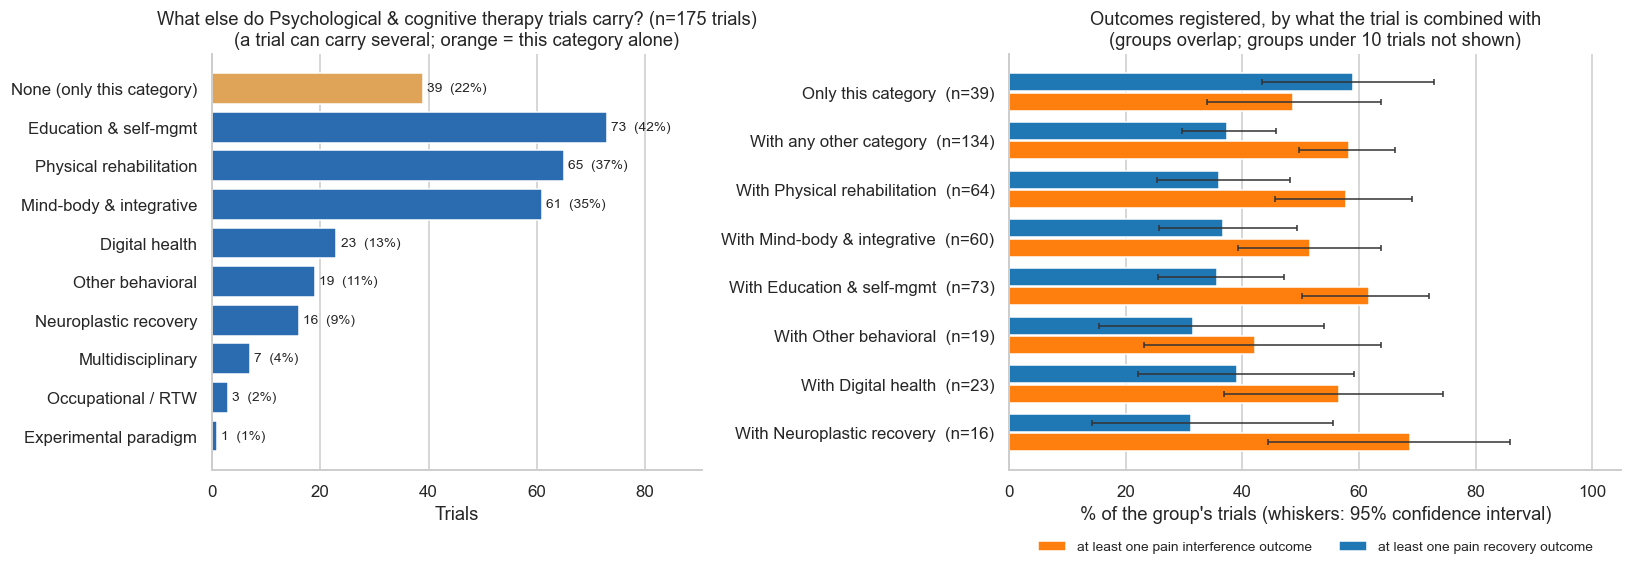

,group,n,pain_interference,pain_recovery,pain_interference_pct,pain_recovery_pct
0,only_this_category,39,19,23,49.0,59.0
1,with_any_other_category,134,78,50,58.0,37.0
2,physical_rehabilitation,64,37,23,58.0,36.0
3,mind_body_integrative,60,31,22,52.0,37.0
4,education_self_management,73,45,26,62.0,36.0
5,other_behavioral_treatment,19,8,6,42.0,32.0
6,digital_health_delivery,23,13,9,57.0,39.0
7,neuroplastic_recovery_therapy,16,11,5,69.0,31.0


In [13]:
FOCUS_CATEGORY = "psychological_cognitive"   # any key of the intervention taxonomy
show(ap.plot_companions(studies, outcomes, FOCUS_CATEGORY, LABELS), f"fig15_companions_{FOCUS_CATEGORY}")
tab = ad.companion_outcome_table(studies, outcomes, FOCUS_CATEGORY)
for col in ("pain_interference", "pain_recovery"):
    tab[f"{col}_pct"] = (100 * tab[col] / tab["n"]).round(0)
ap.save_table(tab, f"tab15_companions_{FOCUS_CATEGORY}", index=False)
display(tab)

### 6c. Does the category aim at different outcomes in different conditions?

For the focus category of 6b, the same question per registered condition (a trial with several conditions counts in each). For every condition: the category's trials **alone**, the category's trials **combined** with other approaches, and **all other behavioral trials** in that condition as a reference (some conditions simply register more pain-recovery outcomes than others, e.g. headache). Groups under 10 trials are drawn **faded and hatched** (their percentages are unstable; read them as an indication only); whiskers are 95% confidence intervals.

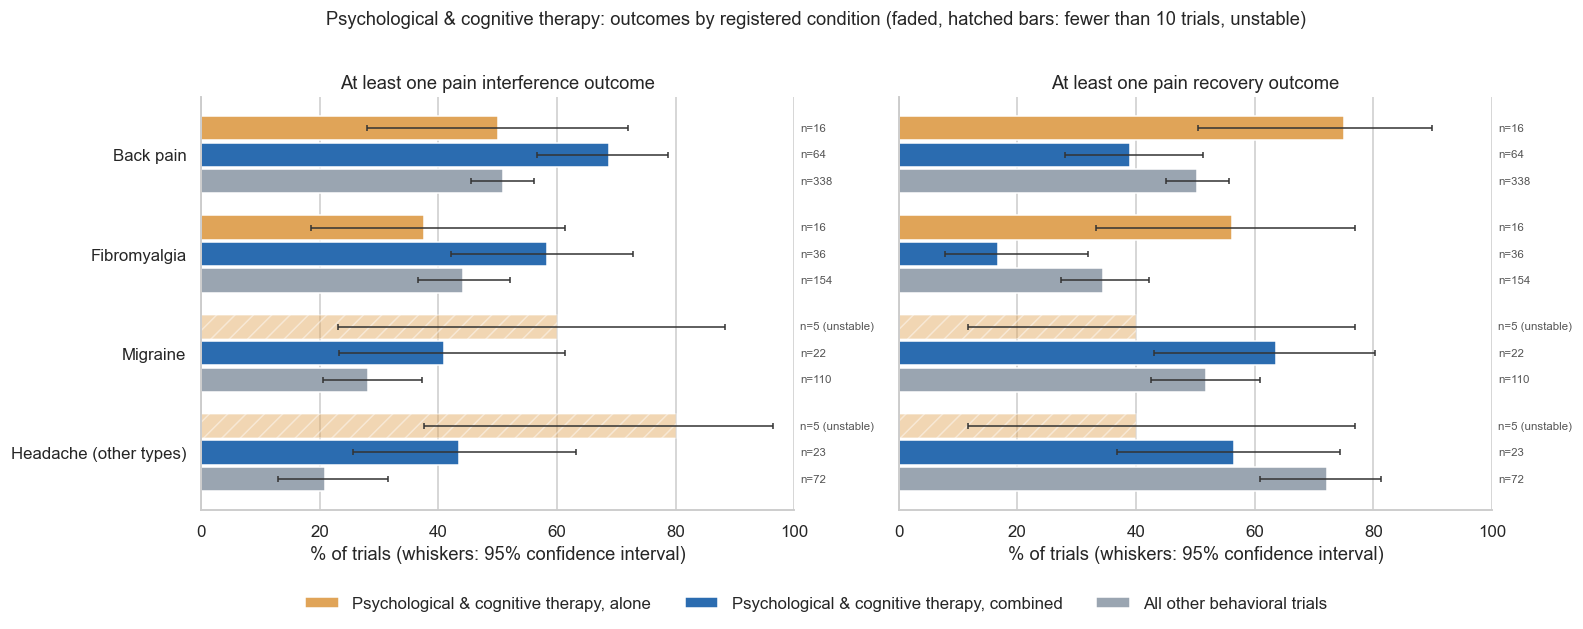

,condition,group,n,pain_interference,pain_recovery,mood,pain_interference_pct,pain_recovery_pct,mood_pct
0,Back pain,all,80,52,37,10,65.0,46.0,12.0
1,Back pain,only_this_category,16,8,12,3,50.0,75.0,19.0
2,Back pain,with_any_other_category,64,44,25,7,69.0,39.0,11.0
3,Back pain,other_trials,338,172,170,17,51.0,50.0,5.0
4,Fibromyalgia,all,52,27,15,18,52.0,29.0,35.0
5,Fibromyalgia,only_this_category,16,6,9,5,38.0,56.0,31.0
6,Fibromyalgia,with_any_other_category,36,21,6,13,58.0,17.0,36.0
7,Fibromyalgia,other_trials,154,68,53,29,44.0,34.0,19.0
8,Migraine,all,27,12,16,5,44.0,59.0,19.0
9,Migraine,only_this_category,5,3,2,1,60.0,40.0,20.0


In [14]:
show(ap.plot_condition_split(studies, outcomes, FOCUS_CATEGORY, LABELS), f"fig16_condition_split_{FOCUS_CATEGORY}")
cond_tab = ad.condition_outcome_table(studies, outcomes, FOCUS_CATEGORY)
for col in ("pain_interference", "pain_recovery", "mood"):
    cond_tab[f"{col}_pct"] = (100 * cond_tab[col] / cond_tab["n"]).round(0)
ap.save_table(cond_tab, f"tab16_condition_split_{FOCUS_CATEGORY}", index=False)
display(cond_tab)

### 6d. CBT, ACT and MBSR inside Psychological & cognitive therapy

How many of the category's trials name CBT, ACT or MBSR in an **active** arm (name + description; comparator arms are skipped). The patterns are descriptive and live in `analysis_data.PSYCH_NAMED_SUBTYPES` (`ACT` is matched as the capitalised abbreviation or the full name, never the word "act"). MBSR is filed under *mind-body* by the intervention taxonomy, so only the few trials that also carry the psychological category appear here. The trials with none of the three are split by what they do name. Subtypes overlap (a trial can be CBT and ACT).

Two versions: first **any** trial naming the therapy (alone or combined with other intervention categories), then only **pure** trials, i.e. those whose sole intervention category is the psychological one. Small groups are drawn faded and hatched.

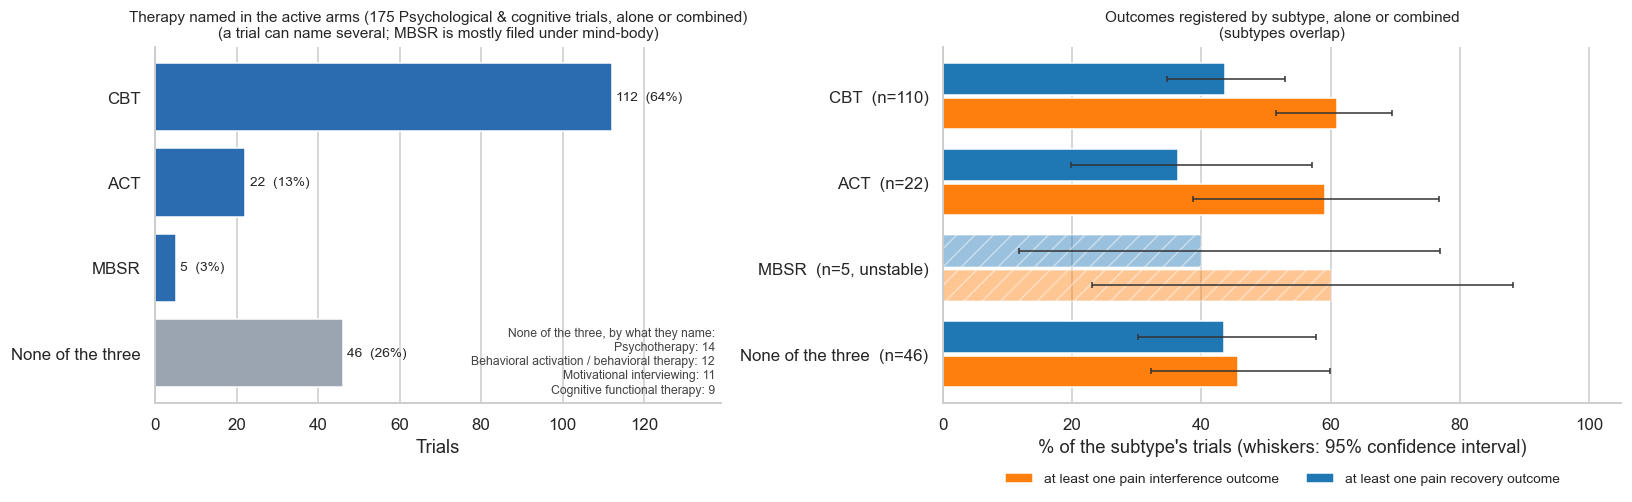

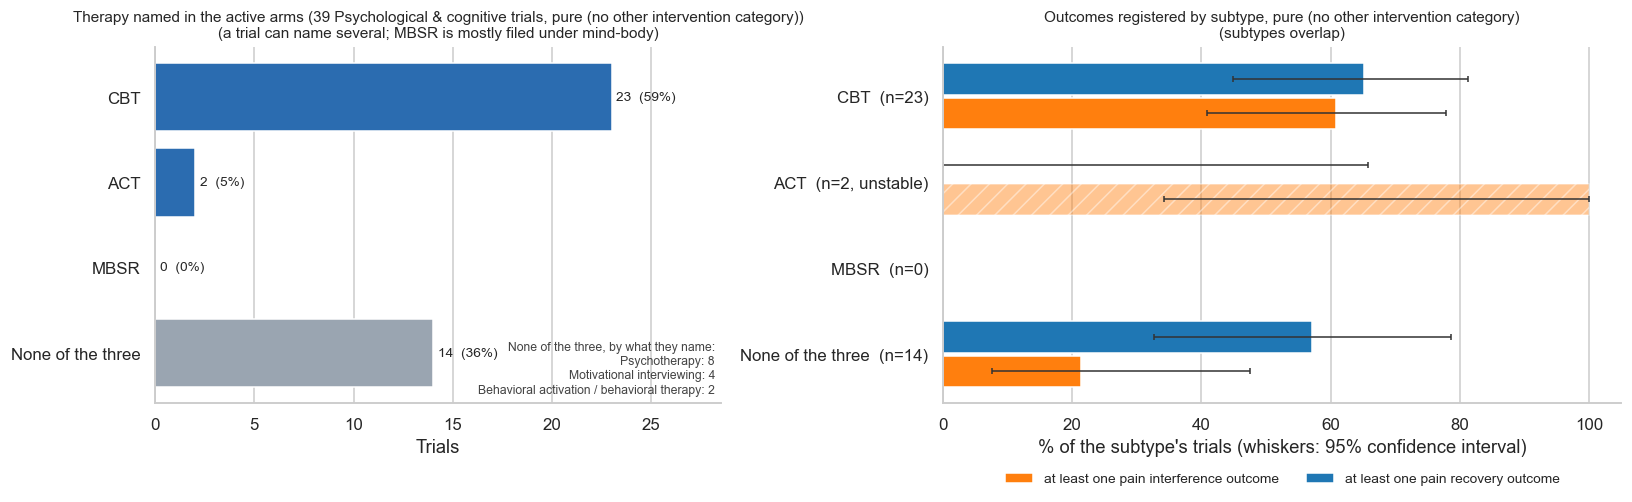

,subtype,trials,n,pain_interference,pain_recovery,pain_interference_pct,pain_recovery_pct
0,CBT,112,110,67,48,61.0,44.0
1,ACT,22,22,13,8,59.0,36.0
2,MBSR,5,5,3,2,60.0,40.0
3,None of the three,46,46,21,20,46.0,43.0


,subtype,trials,n,pain_interference,pain_recovery,pain_interference_pct,pain_recovery_pct
0,CBT,23,23,14,15,61.0,65.0
1,ACT,2,2,2,0,100.0,0.0
2,MBSR,0,0,0,0,NaN,NaN
3,None of the three,14,14,3,8,21.0,57.0


In [15]:
show(ap.plot_psych_subtypes(studies, outcomes), "fig17_psychological_subtypes")
show(ap.plot_psych_subtypes(studies, outcomes, pure_only=True), "fig18_psychological_subtypes_pure")
sub_tab = ad.subtype_outcome_table(studies, outcomes)
for col in ("pain_interference", "pain_recovery"):
    sub_tab[f"{col}_pct"] = (100 * sub_tab[col] / sub_tab["n"]).round(0)
ap.save_table(sub_tab, "tab17_psychological_subtypes", index=False)
display(sub_tab)
sub_pure = ad.subtype_outcome_table(studies, outcomes, pure_only=True)
for col in ("pain_interference", "pain_recovery"):
    sub_pure[f"{col}_pct"] = (100 * sub_pure[col] / sub_pure["n"]).round(0)
ap.save_table(sub_pure, "tab18_psychological_subtypes_pure", index=False)
display(sub_pure)

## Additional views

### Outcome categories overall

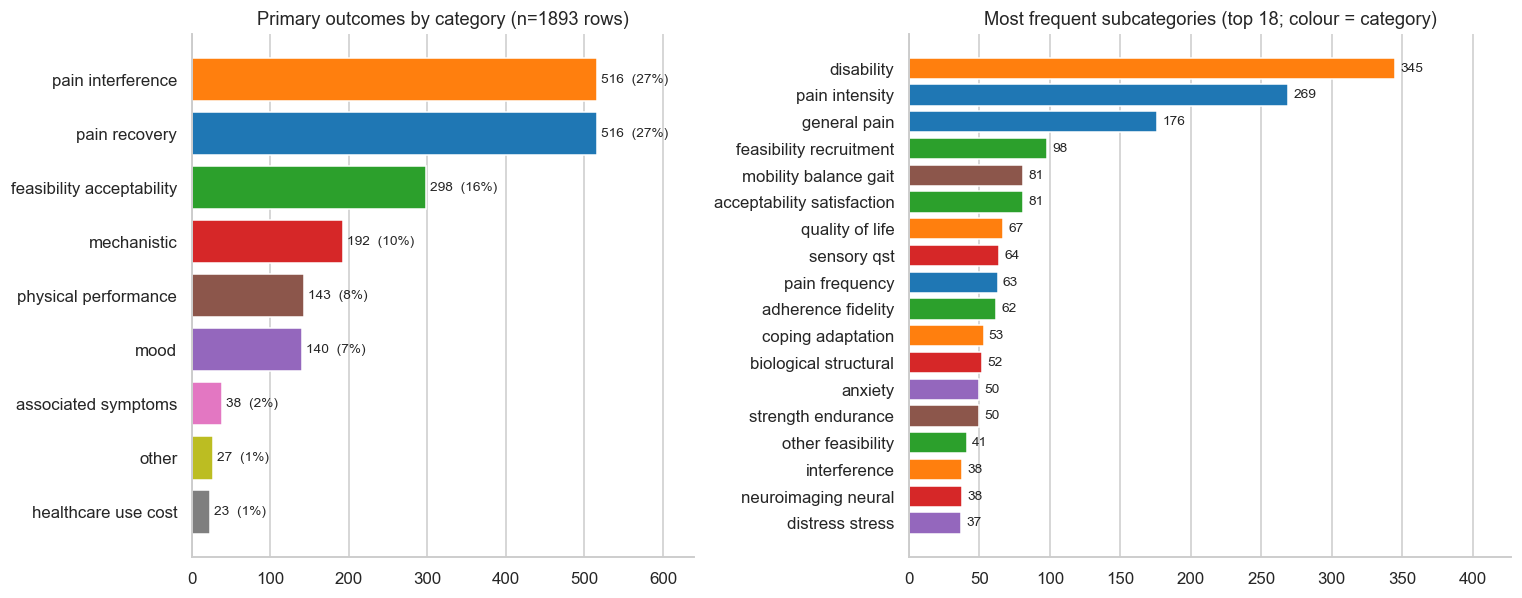

In [16]:
show(ap.plot_outcome_overview(outcomes), "fig07_outcome_overview")
overview = (outcomes[(outcomes["cohort_inclusion_status"] == "included")]
            .groupby(["outcome_category", "outcome_subcategory"]).agg(rows=("outcome_id", "size"), trials=("nct_id", "nunique")))
ap.save_table(overview, "tab07_outcome_overview")

### Outcome categories over time
Share of registered primary outcomes per category, by period of first posting (the research question's time dimension).

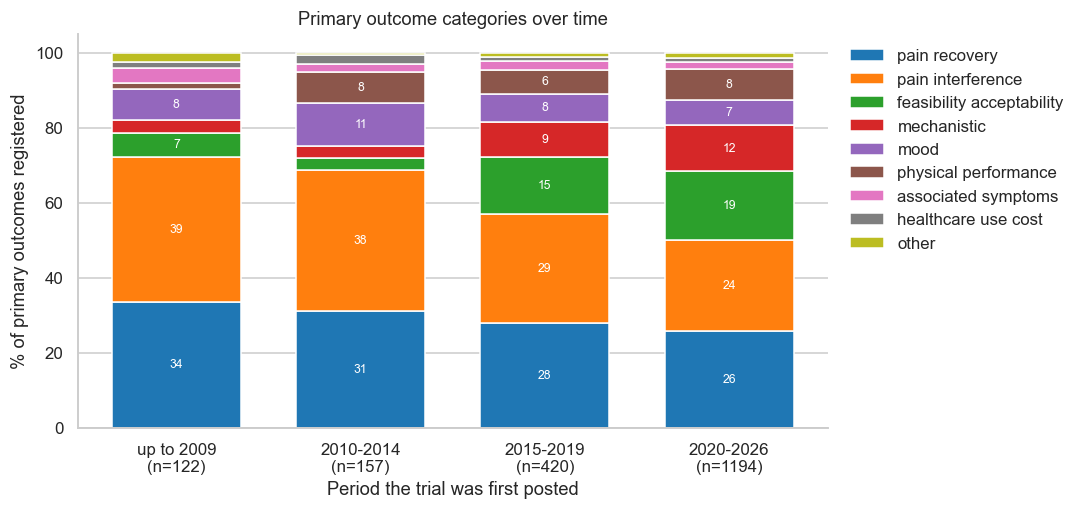

In [17]:
show(ap.plot_outcomes_over_time(studies, outcomes), "fig08_outcomes_over_time")

### Intervention categories over time

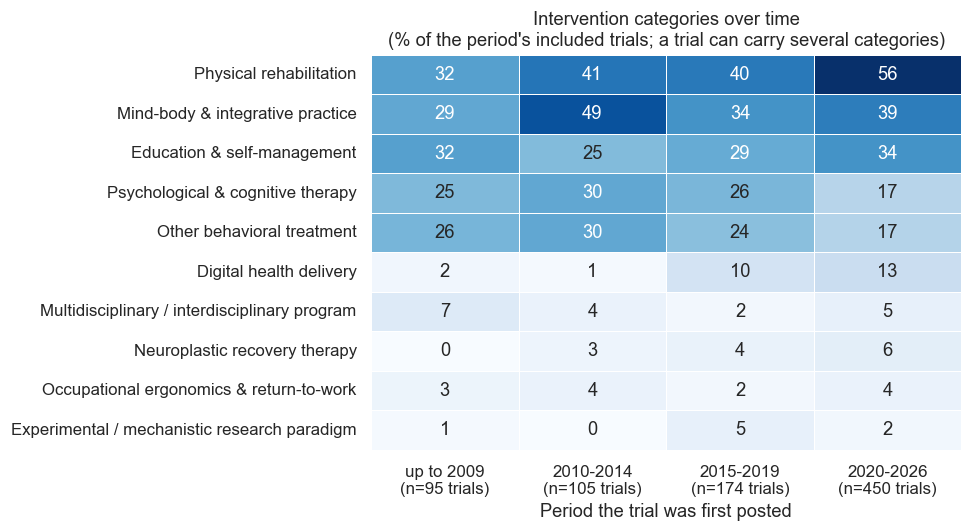

In [18]:
show(ap.plot_interventions_over_time(studies, LABELS), "fig09_interventions_over_time")

### Condition x outcome category
The same cross-tab with the pain condition as the group (a trial listing several conditions counts in each).

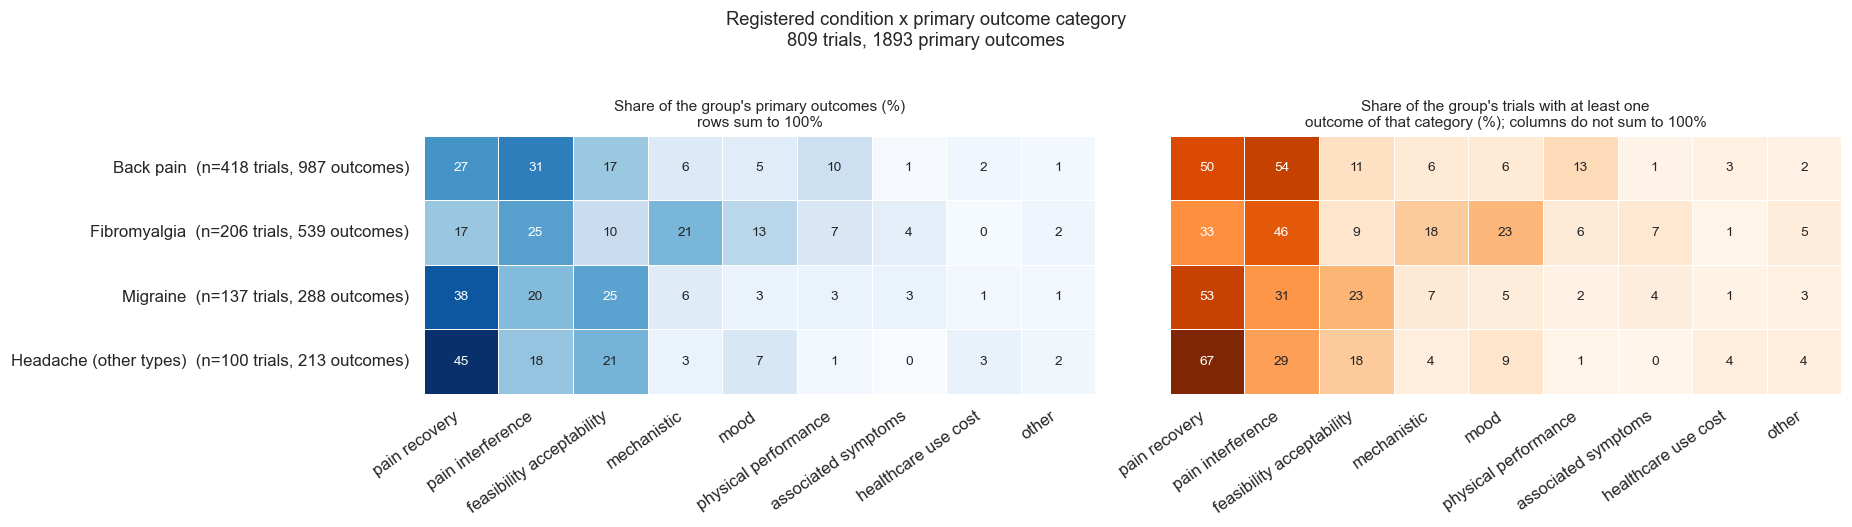

In [19]:
ct_cond = ad.outcome_by_group(studies, outcomes, group="condition_list")
show(ap.plot_crosstab(ct_cond, group_name="Condition", title="Registered condition x primary outcome category"), "fig10_condition_x_outcome")
ap.save_table(ct_cond.row_percent().round(1), "tab10_condition_x_outcome_row_percent")

### Instruments and number of primary outcomes per trial

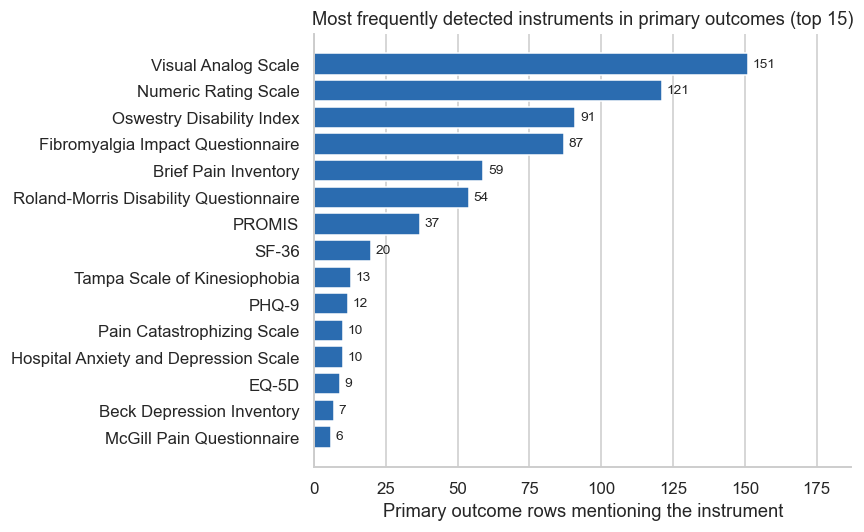

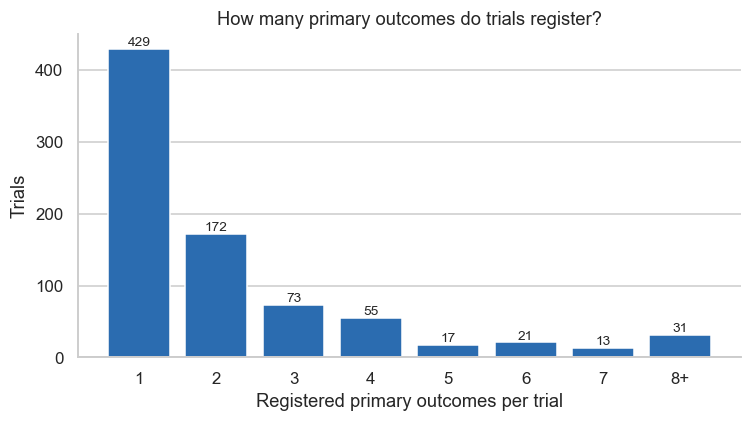

In [20]:
show(ap.plot_top_instruments(outcomes), "fig11_top_instruments")
show(ap.plot_outcomes_per_trial(studies), "fig12_outcomes_per_trial")

## Notes
* Cohort rules: `docs/COHORT_FILTERING_RULES.md`; category patterns and distributions: `docs/category_mapping.md`; columns: `docs/DATA_COLUMNS.md`.
* Outcome and intervention categories are rule-based, descriptive aids, not the researcher's manual conceptual coding; the raw outcome text is in `primary_outcomes.csv`.
* The year is the first-post date on ClinicalTrials.gov, not the trial's start date.